### Step 1 – Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

### Step 2 – Load the Feature-Engineered Dataset

In [2]:
rfm = pd.read_csv("customer_feature_engineered.csv")

print("Dataset Shape:", rfm.shape)

rfm.head()

Dataset Shape: (93358, 19)


,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment,Average_Spending_Per_Order,Customer_Value_Category,Purchase_Intensity,Spending_Category,Customer_Value_Score,Loyalty_Category,Customer_Risk_Category,Customer_Engagement_Score,Purchase_Behaviour,Recency_Category
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,141.90,4,1,3,8,Loyal Customers,141.90,Medium Value,Low,Medium Value,141.90,Medium Loyalty,Low Risk,0.892857,Low Engagement Buyers,Moderate
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,27.19,3,1,1,5,At Risk,27.19,Low Value,Low,Low Value,27.19,Low Loyalty,High Risk,0.869565,Low Engagement Buyers,Moderate
2,0000f46a3911fa3c0805444483337064,536,1,86.22,1,1,2,4,At Risk,86.22,Low Value,Low,Low Value,86.22,Low Loyalty,High Risk,0.186220,Low Engagement Buyers,Inactive
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,43.62,2,1,1,4,At Risk,43.62,Low Value,Low,Low Value,43.62,Low Loyalty,High Risk,0.311526,Low Engagement Buyers,Inactive
4,0004aac84e0df4da2b147fca70cf8255,287,1,196.89,2,1,4,7,Potential Customers,196.89,Medium Value,Low,Medium Value,196.89,Medium Loyalty,Medium Risk,0.347222,Low Engagement Buyers,Inactive


### Step 3 – Select Features for K-Means Clustering

In [3]:
cluster_data = rfm[[
    "Recency",
    "Frequency",
    "Monetary"
]].copy()

print("Selected Features:")
print(cluster_data.head())

print("\nDataset Shape:", cluster_data.shape)

Selected Features:
   Recency  Frequency  Monetary
0      111          1    141.90
1      114          1     27.19
2      536          1     86.22
3      320          1     43.62
4      287          1    196.89

Dataset Shape: (93358, 3)


### Step 4 – Feature Scaling

In [4]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(cluster_data)

print("Scaled Data Shape:", scaled_data.shape)

print("\nFirst 5 Scaled Records:")
print(scaled_data[:5])

Scaled Data Shape: (93358, 3)

First 5 Scaled Records:
[[-0.82535715 -0.1598294  -0.1029416 ]
 [-0.80569671 -0.1598294  -0.60980644]
 [ 1.95987274 -0.1598294  -0.34897276]
 [ 0.54432061 -0.1598294  -0.5372078 ]
 [ 0.3280557  -0.1598294   0.14004068]]


### Step 5 – Find the Optimal Number of Clusters (Elbow Method)

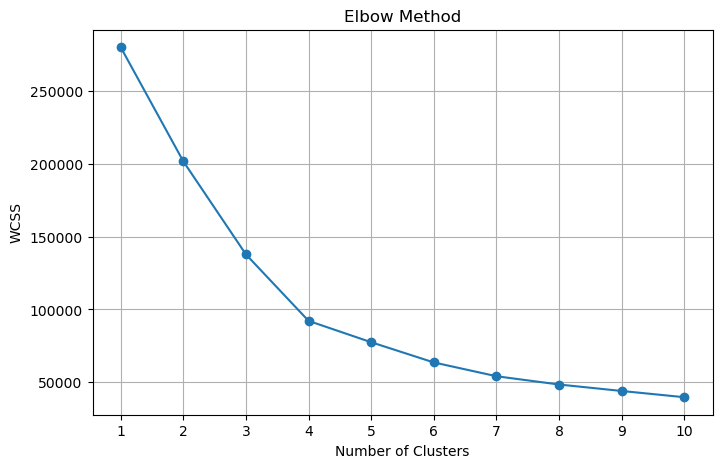

In [5]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(scaled_data)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

### Step 6 – Apply K-Means Clustering

In [6]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(scaled_data)

print("K-Means Clustering Completed!")

print("\nCluster Distribution:")
print(rfm["Cluster"].value_counts().sort_index())

K-Means Clustering Completed!

Cluster Distribution:
Cluster
0    37526
1     2772
2     2418
3    50642
Name: count, dtype: int64


### Step 7 – Evaluate Clustering Performance

In [7]:
score = silhouette_score(
    scaled_data,
    rfm["Cluster"],
    sample_size=10000,
    random_state=42
)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.4926


### Step 8 – Analyze Customer Clusters

In [8]:
cluster_summary = rfm.groupby("Cluster").agg(
    Total_Customers=("customer_unique_id", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

print(cluster_summary)

         Total_Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
Cluster                                                           
0                  37526       386.41           1.00        133.46
1                   2772       219.44           2.11        289.68
2                   2418       238.40           1.01       1160.91
3                  50642       127.07           1.00        134.36


### Step 9 – Assign Customer Segment Names

In [9]:
cluster_names = {
    0: "Inactive Customers",
    1: "Loyal Repeat Customers",
    2: "High-Spending Customers",
    3: "Recent Active Customers"
}

rfm["ML_Customer_Segment"] = rfm["Cluster"].map(cluster_names)

print(rfm[["customer_unique_id", "Cluster", "ML_Customer_Segment"]].head())

print("\nCustomer Segment Distribution:")
print(rfm["ML_Customer_Segment"].value_counts())

                 customer_unique_id  Cluster      ML_Customer_Segment
0  0000366f3b9a7992bf8c76cfdf3221e2        3  Recent Active Customers
1  0000b849f77a49e4a4ce2b2a4ca5be3f        3  Recent Active Customers
2  0000f46a3911fa3c0805444483337064        0       Inactive Customers
3  0000f6ccb0745a6a4b88665a16c9f078        0       Inactive Customers
4  0004aac84e0df4da2b147fca70cf8255        0       Inactive Customers

Customer Segment Distribution:
ML_Customer_Segment
Recent Active Customers    50642
Inactive Customers         37526
Loyal Repeat Customers      2772
High-Spending Customers     2418
Name: count, dtype: int64


### Step 10 – Visualize Customer Segments

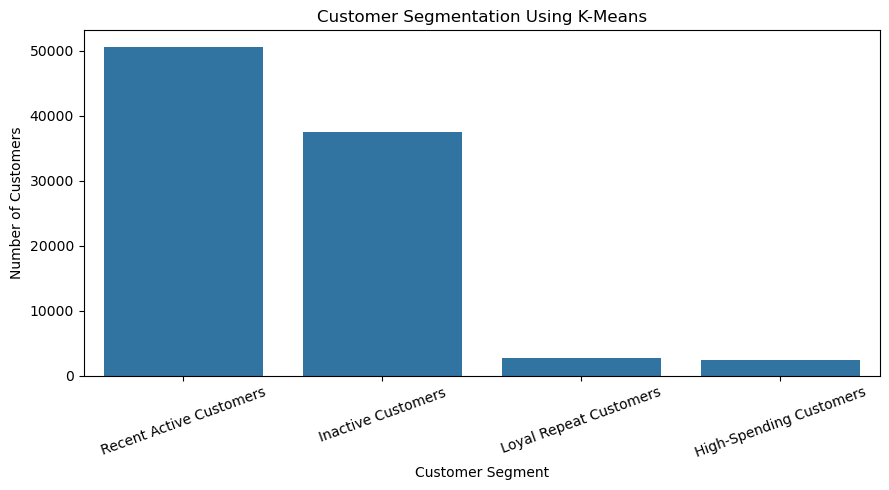

In [10]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=rfm,
    x="ML_Customer_Segment",
    order=rfm["ML_Customer_Segment"].value_counts().index
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Step 11 – Visualize Average Spending Across Clusters

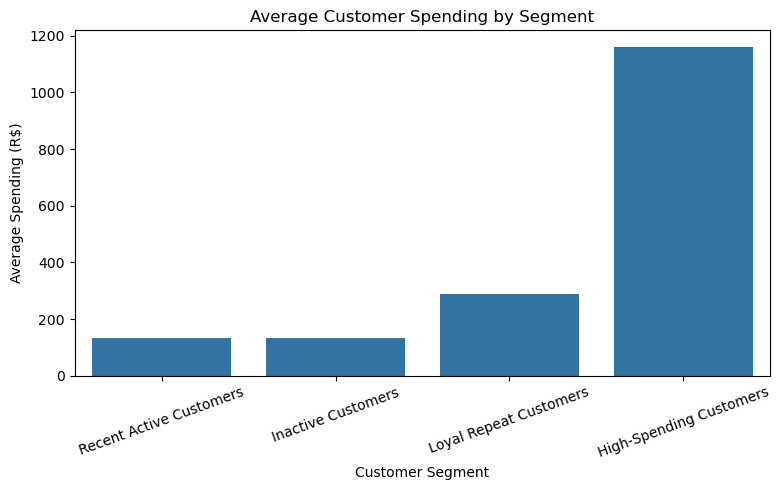

In [11]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=rfm,
    x="ML_Customer_Segment",
    y="Monetary",
    errorbar=None
)

plt.title("Average Customer Spending by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Spending (R$)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Step 12 – Visualize Average Recency by Segment

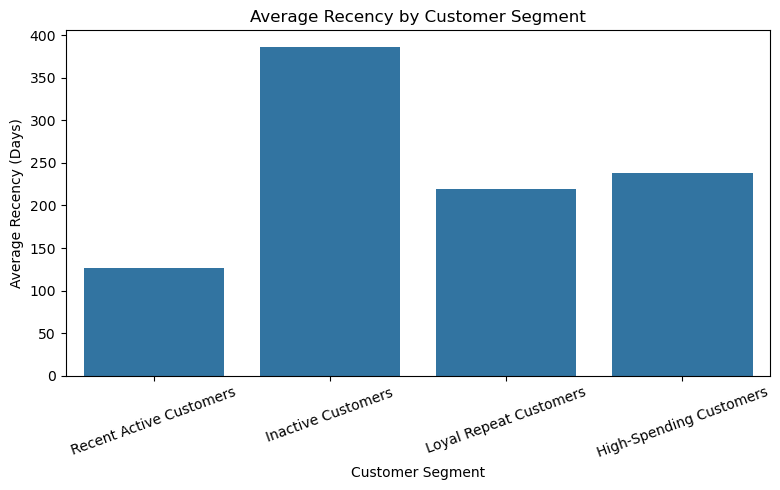

In [12]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=rfm,
    x="ML_Customer_Segment",
    y="Recency",
    errorbar=None
)

plt.title("Average Recency by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Recency (Days)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Step 13 – Visualize Average Purchase Frequency

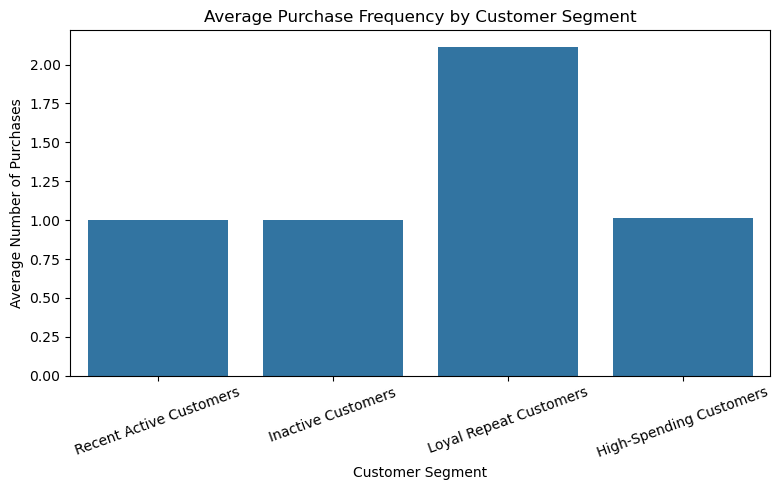

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=rfm,
    x="ML_Customer_Segment",
    y="Frequency",
    errorbar=None
)

plt.title("Average Purchase Frequency by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Number of Purchases")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Step 14 – Evaluate the Final Cluster Summary

In [14]:
final_cluster_summary = rfm.groupby("ML_Customer_Segment").agg(
    Total_Customers=("customer_unique_id", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

final_cluster_summary["Customer_Percentage"] = (
    final_cluster_summary["Total_Customers"] / len(rfm) * 100
).round(2)

final_cluster_summary

,Total_Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Percentage
ML_Customer_Segment,,,,,
High-Spending Customers,2418,238.40,1.01,1160.91,2.59
Inactive Customers,37526,386.41,1.00,133.46,40.20
Loyal Repeat Customers,2772,219.44,2.11,289.68,2.97
Recent Active Customers,50642,127.07,1.00,134.36,54.24


### Step 15 – Export the Final Customer Segmentation Dataset

In [15]:
rfm.to_csv("customer_segmentation_results.csv", index=False)

print("Customer segmentation dataset exported successfully!")

Customer segmentation dataset exported successfully!
